# AI-Ready Dataset Prep: Exoplanet Biosignatures

**Unit of analysis:** one spectrum file; for independent-unit counts and future partitions, group by planet.  
**Potential model task:** identifying absorption features in exoplanet spectra (target/labels still to be defined).  
**Data source:** NASA Exoplanet Archive, Atmospheric Spectroscopy Table; see README for retrieval details and citations.

Run this notebook from the cloned project repository after downloading the files to `ExoData/raw/`.

## Setup

In [1]:
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd()
root = cwd if (cwd / "ExoData" / "raw").exists() else cwd.parent
raw_dir = root / "ExoData" / "raw"
files = sorted(raw_dir.glob("*.tbl"))

assert files, f"No .tbl files found at {raw_dir}. Download the dataset first."
print(f"Found {len(files)} spectra in {raw_dir}")

Found 149 spectra in /Users/kaira/Projects/MLGEO_AU26_Exoplanet_Biosignatures/ExoData/raw


## B1: Diversity

Count independent planets, spectrum files, observation types, and instrument configurations. A single planet can appear in multiple files; 149 spectra are not 149 independent planets.

In [2]:
metadata = []
for file in files:
    info = {"filename": file.name}
    with file.open(encoding="utf-8", errors="replace") as f:
        for line in f:
            if line.startswith("\\"):
                key, _, value = line[1:].partition("=")
                if key.strip():
                    info[key.strip()] = value.strip()
            elif line.startswith("|"):
                break
    metadata.append(info)

planets = {m.get("PL_NAME") for m in metadata if m.get("PL_NAME")}
instruments = Counter(m.get("INSTRUMENT", "Unknown") for m in metadata)
types = Counter(m.get("SPEC_TYPE", "Unknown") for m in metadata)

print("Total spectra:", len(files))
print("Unique planets:", len(planets))
print("Instrument configurations:", len(instruments))
print("\nObservation types:")
for name, count in types.most_common():
    print(f"  {name}: {count} ({count / len(files):.1%})")
print("\nInstrument configurations:")
for name, count in instruments.most_common():
    print(f"  {name}: {count}")

Total spectra: 149
Unique planets: 57
Instrument configurations: 11

Observation types:
  Transmission: 117 (78.5%)
  Direct Imaging: 32 (21.5%)

Instrument configurations:
  Near Infrared Spectrograph (NIRSpec) - G395H: 49
  Near Infrared Spectrograph (NIRSpec): 43
  Near Infrared Imager and Slitless Spectrograph (NIRISS): 21
  Near Infrared Spectrograph (NIRSpec) - PRISM: 21
  Near Infrared Camera (NIRCam): 3
  Mid-Infrared Instrument (MIRI): 3
  Mid-Infrared Instrument (MIRI) - MRS: 2
  Mid-Infrared Instrument (MIRI) - LRS: 2
  Near Infrared Spectrograph (NIRSpec) - G235H: 2
  Near Infrared Spectrograph (NIRSpec) - G395M: 2
  Near Infrared Spectrograph (NIRSpec) - G140H: 1


Observed results for the initial downloaded batch (verify by rerunning): 149 spectra from 57 unique planets; 117 transmission and 32 direct-imaging spectra; 11 instrument configurations. These counts describe the downloaded subset, not the whole archive. Because the same planet can appear in multiple spectra, split membership should be assigned by planet rather than by wavelength row or individual file.

## B2: Distribution (partial)

First examine spectrum length and observation type imbalance. To finish B2, also inspect distributions of the main physical inputs (e.g., wavelength and measured flux or transit depth) and the model target once its definition is finalized.

The dataset is also imbalanced across observation methods,
with transmission spectra making up 78.5% of the data and
direct-imaging spectra making up 21.5%.

Because our dataset does not yet contain verified biosignature
labels, we cannot calculate the distribution of positive and
negative biosignature classes.

This is a limitation for supervised classification and will
need to be addressed before training a biosignature detector.

In [3]:
def spectrum_rows(file):
    """Return non-header measurement rows from an IPAC .tbl file."""
    lines = file.read_text(encoding="utf-8", errors="replace").splitlines()
    header_idx = next((i for i, line in enumerate(lines) if line.startswith("|")), None)
    if header_idx is None:
        return []
    return [line for line in lines[header_idx + 1:]
            if line.strip() and not line.lstrip().startswith(("|", "\\"))]

counts = [len(spectrum_rows(file)) for file in files]
print("Spectra analyzed:", len(counts))
print("Minimum data points:", min(counts))
print("Maximum data points:", max(counts))
print("Median data points:", np.median(counts))

Spectra analyzed: 149
Minimum data points: 106
Maximum data points: 17434
Median data points: 241.0


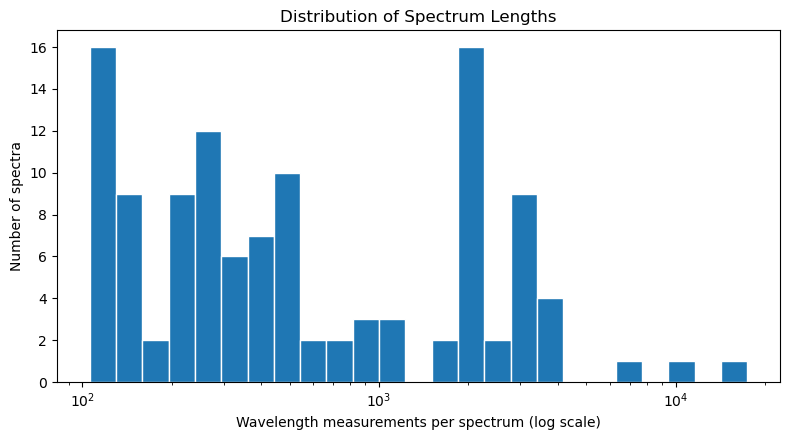

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.logspace(np.log10(min(counts)), np.log10(max(counts)), 26)
ax.hist(counts, bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Wavelength measurements per spectrum (log scale)")
ax.set_ylabel("Number of spectra")
ax.set_title("Distribution of Spectrum Lengths")
fig.tight_layout()
plt.show()

Observed results for the initial downloaded batch (verify by rerunning): minimum 106, median 241, maximum 17,434 measurements per spectrum. The distribution is strongly right-skewed: most spectra are short, with a small number containing thousands of points. Spectrum length is a property of the input data, not a biosignature class distribution. The observation-type split is also imbalanced (117 transmission vs. 32 direct-imaging files).

### Wavelength coverage (additional B2 evidence)

For files whose first column is `CENTRALWAVELNG`, summarize the minimum and maximum wavelengths. This is a simple first check, not interpolation onto a common wavelength grid.

Files with parseable CENTRALWAVELNG: 149/149
Overall observed wavelength span: 0.5202–24.48 microns


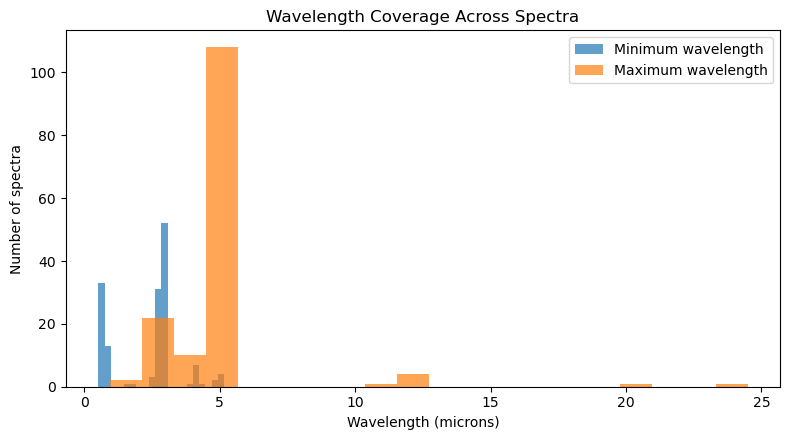

In [5]:
coverage = []
for file in files:
    lines = file.read_text(encoding="utf-8", errors="replace").splitlines()
    header = next((line for line in lines if line.startswith("|")), "")
    names = [s.strip() for s in header.strip("|").split("|")]
    if not names or names[0] != "CENTRALWAVELNG":
        continue
    waves = []
    for row in spectrum_rows(file):
        try:
            wave = float(row.split()[0])
            if np.isfinite(wave):
                waves.append(wave)
        except (ValueError, IndexError):
            pass
    if waves:
        coverage.append((file.name, min(waves), max(waves)))

print(f"Files with parseable CENTRALWAVELNG: {len(coverage)}/{len(files)}")
if coverage:
    mins = np.array([a for _, a, _ in coverage])
    maxs = np.array([b for _, _, b in coverage])
    print(f"Overall observed wavelength span: {mins.min():.4g}–{maxs.max():.4g} microns")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(mins, bins=20, alpha=0.7, label="Minimum wavelength")
    ax.hist(maxs, bins=20, alpha=0.7, label="Maximum wavelength")
    ax.set(xlabel="Wavelength (microns)", ylabel="Number of spectra", title="Wavelength Coverage Across Spectra")
    ax.legend()
    fig.tight_layout()
    plt.show()

## B3: Noise
Of the 149 spectra in our dataset, 143 (96.0%) contain usable
reported measurement uncertainties, while 6 (4.0%) do not.

We calculated the median relative uncertainty using the
reported error values divided by the corresponding measurements.
The median across spectra was approximately 2.69%.

These uncertainties provide an initial estimate of measurement
noise. However, they do not fully separate instrumental noise
from natural variability, and uncertainty values may differ
depending on the instrument and observation method.

Our analysis uses the ERR1 columns only and does not yet
account for all upper limits or asymmetric uncertainties.

In [6]:
import numpy as np
import pandas as pd

def load_numeric_columns(file):
    lines = file.read_text(errors="replace").splitlines()

    header_index = next(
        i for i, line in enumerate(lines)
        if line.startswith("|")
    )

    header = lines[header_index]
    bars = [i for i, c in enumerate(header) if c == "|"]
    spans = list(zip(bars[:-1], bars[1:]))
    names = [
        header[a + 1:b].strip()
        for a, b in spans
    ]

    data = {name: [] for name in names}

    for line in lines[header_index + 1:]:
        if not line.strip() or line.startswith(("|", "\\")):
            continue

        for name, (a, b) in zip(names, spans):
            try:
                value = float(line[a + 1:b].strip())
                if not np.isfinite(value):
                    value = np.nan
            except ValueError:
                value = np.nan

            data[name].append(value)

    return {
        name: np.array(values, dtype=float)
        for name, values in data.items()
    }


results = []

for file in files:
    data = load_numeric_columns(file)

    if "PL_TRANDEP" in data:
        signal = "PL_TRANDEP"
    elif "FLAM" in data:
        signal = "FLAM"
    else:
        continue

    values = data[signal]
    errors = data.get(signal + "ERR1", np.full(len(values), np.nan))

    valid = (
        np.isfinite(values)
        & np.isfinite(errors)
        & (values != 0)
    )

    relative_error = (
        np.median(np.abs(errors[valid] / values[valid]))
        if valid.any() else np.nan
    )

    results.append({
        "file": file.name,
        "signal": signal,
        "total_points": len(values),
        "points_with_errors": int(valid.sum()),
        "median_relative_error": relative_error
    })

noise_df = pd.DataFrame(results)

print("Spectra analyzed:", len(noise_df))
print("Spectra with usable errors:",
      (noise_df["points_with_errors"] > 0).sum())
print("Spectra without usable errors:",
      (noise_df["points_with_errors"] == 0).sum())

print("\nBy signal type:")
print(noise_df.groupby("signal")["points_with_errors"].agg(
    ["count", "sum"]
))

print("\nMedian relative error:")
print(noise_df["median_relative_error"].median())

Spectra analyzed: 149
Spectra with usable errors: 143
Spectra without usable errors: 6

By signal type:
            count    sum
signal                  
FLAM           32  64388
PL_TRANDEP    117  65106

Median relative error:
0.026939871807794825


## B4: Augmentation

**Physically valid augmentation**

A physically reasonable augmentation would be to add small perturbations
to the measured signal based on the reported measurement uncertainties.
This would simulate repeated noisy measurements of the same spectrum
without changing the underlying wavelength positions of spectral features.

**Physically invalid augmentation**

A physically invalid augmentation would be to randomly shift absorption
features to different wavelengths. This would break the physics, because
molecules absorb light at characteristic wavelengths. Moving a feature
without a physical reason would change its scientific meaning.

Any augmented copies of a spectrum should remain in the same
training/validation/test partition as the original spectrum to avoid
data leakage.

## B5: Labels

The dataset contains spectra and rich metadata from the NASA Exoplanet
Archive, including references, instruments, and observation types.

However, the dataset does not currently contain a verified biosignature
label for every spectrum. This means we do not yet have a fully defined
supervised-learning target for biosignature detection.

The labels used in the project smoke test were synthetic and were created
only to verify that the software environment and basic machine-learning
pipeline run successfully. They are not scientifically meaningful labels.

If we later build a supervised model, we will need a consistent labeling
scheme, such as identifying specific molecular absorption features or
confirmed detections from the literature. Otherwise, the spectra may be
better suited for unsupervised or self-supervised learning.

## B6: Dimensionality

We treat each spectrum as one sample rather than treating each wavelength
measurement as an independent sample.

Across the full raw dataset, we have:

- **N = 149 spectra**
- **Raw dataset size = 96.57 MB**

Because the spectra have different wavelength ranges and different numbers
of measurements, there is no single common wavelength interval shared by
all 149 spectra. Therefore, dimensionality reduction on the full dataset
would require a more complex harmonization step.

For an exploratory PCA, we selected a compatible subset of 31 transmission
spectra observed with **JWST NIRSpec G395H**, excluding the two TOI-732 c
spectra that broke the common overlap.

For this subset, we interpolated each spectrum onto a common grid of
100 wavelength points over the shared wavelength range **2.8843–5.0725 μm**.

This gave:

- **N = 31**
- **D = 100**
- **N/D = 0.31**

The PCA results showed that **1 principal component explained at least 90%
of the variance** in this subset. This suggests that the spectra in this
compatible subset are highly similar in their overall shapes over the
shared wavelength range.

This PCA is exploratory only. For a final modeling pipeline, preprocessing
steps such as interpolation, scaling, and PCA must be fit on the training
set only after train/validation/test partitions are defined.

Usable spectra: 31
Common wavelength range: 2.8843 to 5.0725
N: 31
D: 100
N/D: 0.31
Components for 90% variance: 1


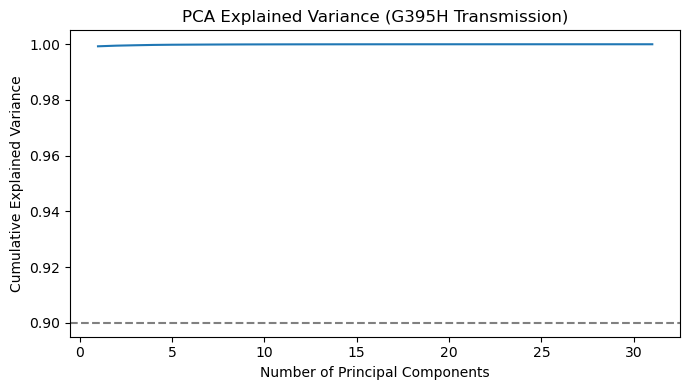

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

spectra = []

for file in files:
    lines = file.read_text(errors="replace").splitlines()

    metadata = {}
    for line in lines:
        if line.startswith("\\"):
            key, _, value = line[1:].partition("=")
            metadata[key.strip()] = value.strip()
        elif line.startswith("|"):
            break

    if metadata.get("SPEC_TYPE") != "Transmission":
        continue

    if metadata.get("INSTRUMENT") != "Near Infrared Spectrograph (NIRSpec) - G395H":
        continue

    if metadata.get("PL_NAME") == "TOI-732 c":
        continue

    data = load_numeric_columns(file)

    if "CENTRALWAVELNG" not in data or "PL_TRANDEP" not in data:
        continue

    w = data["CENTRALWAVELNG"]
    y = data["PL_TRANDEP"]

    valid = np.isfinite(w) & np.isfinite(y)
    w, y = w[valid], y[valid]

    if len(w) < 10:
        continue

    order = np.argsort(w)
    w, y = w[order], y[order]

    w, unique_idx = np.unique(w, return_index=True)
    y = y[unique_idx]

    spectra.append((file.name, w, y))

print("Usable spectra:", len(spectra))

lower = max(w.min() for _, w, y in spectra)
upper = min(w.max() for _, w, y in spectra)

print("Common wavelength range:", round(lower, 4), "to", round(upper, 4))

grid = np.linspace(lower, upper, 100)

X = np.array([
    np.interp(grid, w, y)
    for _, w, y in spectra
])

N, D = X.shape

print("N:", N)
print("D:", D)
print("N/D:", N / D)

pca = PCA()
pca.fit(X)

cumulative = np.cumsum(pca.explained_variance_ratio_)
components_90 = np.searchsorted(cumulative, 0.90) + 1

print("Components for 90% variance:", components_90)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative)
plt.axhline(0.90, linestyle="--", color="gray")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance (G395H Transmission)")
plt.tight_layout()
plt.show()

## B7: Partitions

We split our dataset by planet to prevent data leakage between training, validation, and testing.

- **Training:** 56 spectra from 26 planets.
- **Validation:** 20 spectra from 7 planets.
- **Test:** 33 spectra from 11 planets, observed using NIRSpec G395H.
- **Excluded:** 40 spectra not used in this experiment.

Training and validation contain transmission spectra from instrument configurations other than G395H. The test set uses G395H transmission spectra to evaluate how well the model generalizes to a different instrument configuration.

We kept all assigned observations of each planet in a single partition to avoid data leakage. Direct-imaging spectra and some observations of test planets were excluded.

We saved the partition assignments in `data/ai_ready/partitions.csv` and used a random seed of 42 for reproducibility.

The planet-level leakage check passed. Before training a model, preprocessing steps such as scaling, imputation, and PCA must be fitted on training data only and then applied to validation and test data.

In [8]:

from pathlib import Path
from collections import Counter, defaultdict
import csv
import random

# Folder paths (notebook is inside notebooks/)
raw_dir = Path("../ExoData/raw")
output_dir = Path("../data/ai_ready")
output_dir.mkdir(parents=True, exist_ok=True)

records = []

for file in sorted(raw_dir.glob("*.tbl")):
    metadata = {}

    with open(file) as f:
        for line in f:
            if line.startswith("\\"):
                key, _, value = line[1:].partition("=")
                metadata[key.strip()] = value.strip()
            elif line.startswith("|"):
                break

    records.append({
        "filename": file.name,
        "planet": metadata.get("PL_NAME", ""),
        "type": metadata.get("SPEC_TYPE", ""),
        "instrument": metadata.get("INSTRUMENT", ""),
        "split": "excluded"
    })

if not records:
    raise ValueError("No .tbl files found. Check raw_dir.")

transmission = [
    r for r in records
    if r["type"] == "Transmission"
    and r["planet"]
    and r["instrument"]
]

# Test set: planets observed using G395H
test_planets = {
    r["planet"]
    for r in transmission
    if r["instrument"].endswith("G395H")
}

# Other planets available for train/validation
available_planets = sorted({
    r["planet"]
    for r in transmission
    if r["planet"] not in test_planets
    and not r["instrument"].endswith("G395H")
})

# Random 80/20 planet-level split
rng = random.Random(42)
rng.shuffle(available_planets)

if len(available_planets) < 2 or not test_planets:
    raise ValueError("Not enough planets for splitting.")

n_val = max(1, round(0.2 * len(available_planets)))

val_planets = set(available_planets[:n_val])
train_planets = set(available_planets[n_val:])

for r in records:
    if r["type"] != "Transmission":
        continue

    if r["planet"] in test_planets:
        if r["instrument"].endswith("G395H"):
            r["split"] = "test"

    elif r["planet"] in train_planets:
        r["split"] = "train"

    elif r["planet"] in val_planets:
        r["split"] = "validation"

planet_splits = defaultdict(set)

for r in records:
    if r["split"] != "excluded":
        planet_splits[r["planet"]].add(r["split"])

assert all(
    len(splits) == 1
    for splits in planet_splits.values()
)

# Check that G395H is held out from training/validation
assert all(
    not r["instrument"].endswith("G395H")
    for r in records
    if r["split"] in ("train", "validation")
)

output_file = output_dir / "partitions.csv"

with open(output_file, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=records[0].keys())
    writer.writeheader()
    writer.writerows(records)


print("B7Partition Results")

for split in ("train", "validation", "test", "excluded"):
    subset = [r for r in records if r["split"] == split]
    planets = {r["planet"] for r in subset}

    print(f"{split}: {len(subset)} spectra, {len(planets)} planets")

print("\nTotal files:", len(records))
print("Leakage check: PASSED")
print("Saved:", output_file)


B7 — Partition Results
train: 56 spectra, 26 planets
validation: 20 spectra, 7 planets
test: 33 spectra, 11 planets
excluded: 40 spectra, 16 planets

Total files: 149
Leakage check: PASSED
Saved: ../data/ai_ready/partitions.csv


In [11]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Use spectrum length as a simple example feature
lengths = {
    file.name: len(spectrum_rows(file))
    for file in files
}

# Get features for each partition
X_train = np.array([
    [lengths[r["filename"]]]
    for r in records if r["split"] == "train"
])

X_val = np.array([
    [lengths[r["filename"]]]
    for r in records if r["split"] == "validation"
])

X_test = np.array([
    [lengths[r["filename"]]]
    for r in records if r["split"] == "test"
])

# Fit the scaler ONLY on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Apply the SAME scaler to validation and test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train_scaled))
print("Validation samples:", len(X_val_scaled))
print("Test samples:", len(X_test_scaled))

print("Scaler fitted on training data only: PASSED")
print("Training mean used:", scaler.mean_[0])
print("Training standard deviation used:", scaler.scale_[0])

Training samples: 56
Validation samples: 20
Test samples: 33
Scaler fitted on training data only: PASSED
Training mean used: 442.125
Training standard deviation used: 654.8479120730466


### Train-only preprocessing

To demonstrate leakage-safe preprocessing, we used the number of wavelength measurements per spectrum as an example feature.

We fitted a StandardScaler using only the 56 training spectra. We then applied the same scaler to the 20 validation spectra and 33 test spectra without recalculating the mean or standard deviation.

This demonstrates how preprocessing statistics can be calculated without using information from the validation or test sets.

The final model will require additional preprocessing of the spectral measurements, using the same train-only principle.